# 📊 EMAT Hybrid Pipeline — Phân tích & Đánh giá Mô hình

**Dự án:** Stock Price Prediction using EMAT + HMM + GARCH + Sentiment + Hybrid DQN-PPO  
**Mã cổ phiếu:** AAPL, MSFT, JPM, XOM, VCB, HPG, FPT (+ GOOGL, META, VNM cho baseline)  
**Thời gian dữ liệu:** 2009-01-01 → 2025-12-31

---

## 0. Setup & Configuration

In [3]:
import sys, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path

warnings.filterwarnings('ignore')

# Thêm src vào path
sys.path.insert(0, str(Path('.').resolve() / 'src'))
import config

# Cấu hình matplotlib chuẩn IEEE
plt.style.use('default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'figure.facecolor': 'white',
})

config.print_config()
print(f"\nDevice: {config.DEVICE}")
print(f"Symbols: {config.SYMBOLS}")

CẤU HÌNH PIPELINE
  Mã cổ phiếu     : ['AAPL', 'MSFT', 'JPM', 'XOM', 'VCB', 'HPG', 'FPT']
  Device           : cuda
  Split ratio      : 0.7/0.1/0.2
  EMAT input_dim   : 12
  EMAT d_model     : 64
  EMAT window      : 15
  Prediction heads : [1, 3, 5]
  State dim        : 31
  Sentiment model  : xlm-roberta-base
  Num actions      : 7
  DQN episodes     : 500
  PPO episodes     : 300

Device: cuda
Symbols: ['AAPL', 'MSFT', 'JPM', 'XOM', 'VCB', 'HPG', 'FPT']


## Phase 1: Chuẩn bị & Chia dữ liệu

Chia dữ liệu theo tỷ lệ **70/10/20** (Train/Val/Test) theo thứ tự thời gian.

In [4]:
from phase1_data_split import run as phase1_run
phase1_run()


  PHASE 1: CHUẨN BỊ DỮ LIỆU ĐỒNG BỘ

  ĐANG XỬ LÝ: AAPL
  Prices      :   4275 dòng | 2009-01-02 → 2025-12-30
  EMAT Dataset:   4275 dòng | 2009-01-02 → 2025-12-30
  News EN     :   2082 dòng
  News VI     :    231 dòng
  Sentiment VI:   1020 dòng

  Mốc chia thời gian:
    Train : ... → 2020-11-18
    Val   : 2020-11-18 → 2022-08-02
    Test  : 2022-08-02 → ...

  Kết quả chia dữ liệu cho AAPL:
  Split    |   Prices |     News |  Sentiment
  ---------+----------+----------+-----------
  train    |     2992 |      507 |          0
  val      |      427 |        4 |          0
  test     |      856 |     1802 |       1020
  ✔ Tổng kiểm tra: 4275 dòng prices, không overlap.

  ĐANG XỬ LÝ: MSFT
  Prices      :   4275 dòng | 2009-01-02 → 2025-12-30
  EMAT Dataset:   4275 dòng | 2009-01-02 → 2025-12-30
  News EN     :   1612 dòng
  News VI     :    276 dòng
  Sentiment VI:    276 dòng

  Mốc chia thời gian:
    Train : ... → 2020-11-18
    Val   : 2020-11-18 → 2022-08-02
    Test  : 2022-0

{'AAPL': {'train': {'prices': 2992, 'news': 507, 'sentiment': 0},
  'val': {'prices': 427, 'news': 4, 'sentiment': 0},
  'test': {'prices': 856, 'news': 1802, 'sentiment': 1020}},
 'MSFT': {'train': {'prices': 2992, 'news': 20, 'sentiment': 20},
  'val': {'prices': 427, 'news': 17, 'sentiment': 17},
  'test': {'prices': 856, 'news': 1851, 'sentiment': 239}},
 'JPM': {'train': {'prices': 2992, 'news': 2868, 'sentiment': 7},
  'val': {'prices': 427, 'news': 16, 'sentiment': 8},
  'test': {'prices': 856, 'news': 1748, 'sentiment': 217}},
 'XOM': {'train': {'prices': 2992, 'news': 638, 'sentiment': 40},
  'val': {'prices': 427, 'news': 26, 'sentiment': 26},
  'test': {'prices': 856, 'news': 1573, 'sentiment': 111}},
 'VCB': {'train': {'prices': 2873, 'news': 1094, 'sentiment': 1071},
  'val': {'prices': 410, 'news': 201, 'sentiment': 194},
  'test': {'prices': 822, 'news': 687, 'sentiment': 589}},
 'HPG': {'train': {'prices': 2879, 'news': 1470, 'sentiment': 1441},
  'val': {'prices': 412,

### Trực quan hóa phân bố dữ liệu

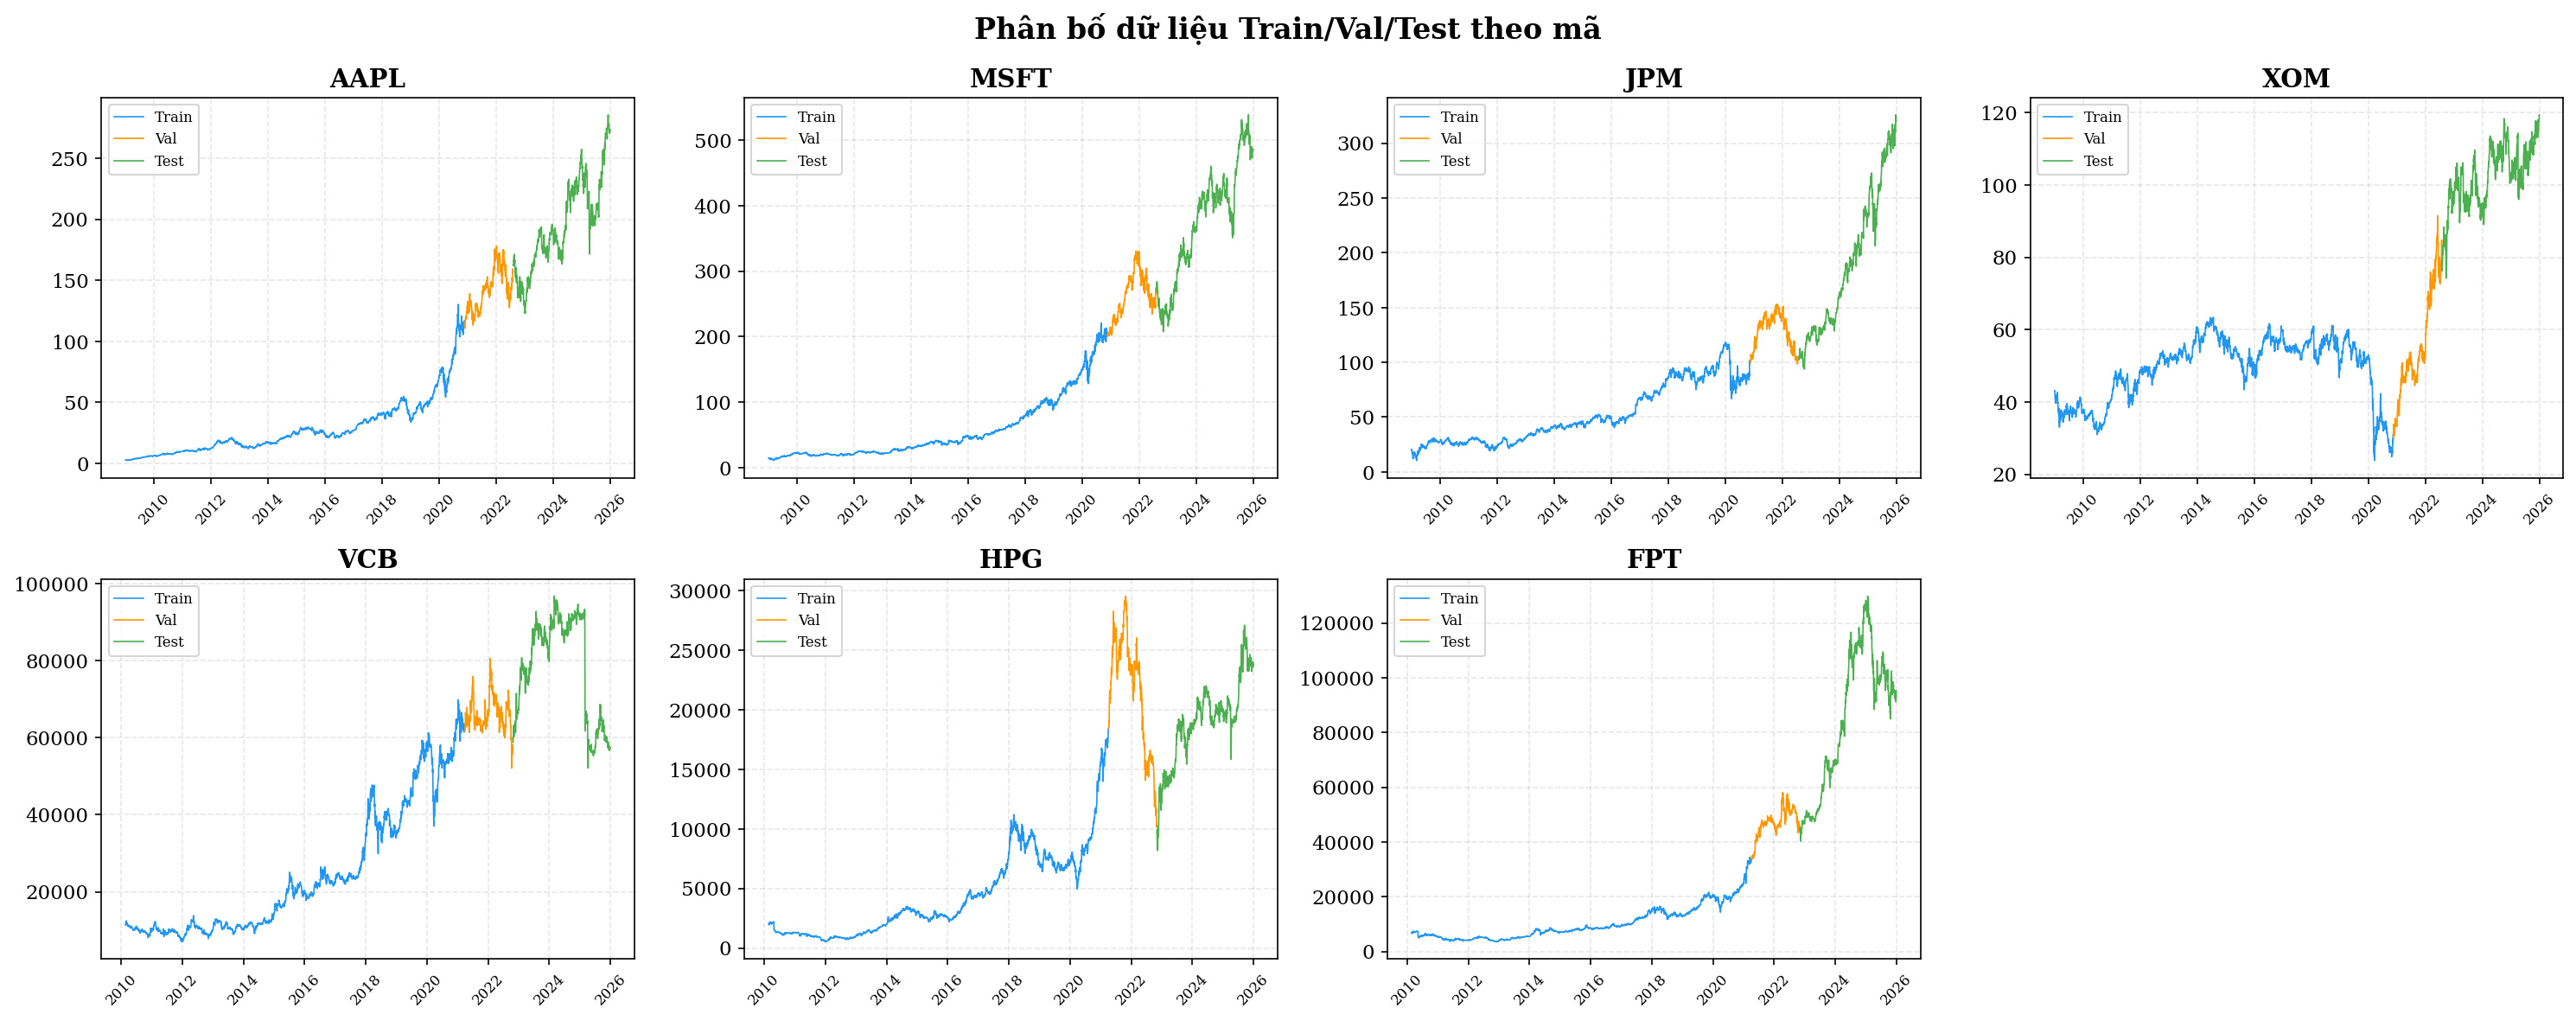


Thống kê phân bố:
  train: 7 symbols
  val: 7 symbols
  test: 7 symbols


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for i, symbol in enumerate(config.SYMBOLS):
    ax = axes[i]
    for split, color, label in [('train', '#2196F3', 'Train'), ('val', '#FF9800', 'Val'), ('test', '#4CAF50', 'Test')]:
        price_path = config.DATA_DIR / split / f"{symbol}_prices.csv"
        if price_path.exists():
            df = pd.read_csv(price_path)
            df['Date'] = pd.to_datetime(df['Date'])
            ax.plot(df['Date'], df['Close'], color=color, label=label, linewidth=0.8)
    ax.set_title(symbol, fontweight='bold')
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=45, labelsize=8)

axes[-1].axis('off')
fig.suptitle('Phân bố dữ liệu Train/Val/Test theo mã', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(str(config.PLOTS_DIR / 'fig0_data_split.png'))
plt.show()

# Thống kê
print("\nThống kê phân bố:")
for split in ['train', 'val', 'test']:
    total = sum(1 for s in config.SYMBOLS 
                for _ in [1] if (config.DATA_DIR / split / f"{s}_prices.csv").exists())
    print(f"  {split}: {total} symbols")

## Phase 2.1: EMAT (Time2Vec + Transformer)

EMAT dự đoán return 1d, 3d, 5d từ chuỗi thời gian OHLCV + Technical Indicators.

**Kiến trúc:** Time2Vec Embedding → Transformer Encoder → Multi-Head Regression

In [6]:
from phase2_train_emat import run as emat_run
emat_run()


  PHASE 2.1: HUẤN LUYỆN EMAT (Multi-Task Transformer)
  Device: cuda

  Đang load dữ liệu train...
  Train: 20466 samples, window=15, features=12
  Đang load dữ liệu val...
  Val  : 2809 samples

  Tổng parameters: 66,563
  Epoch   1/100 | Train Loss: 1.6810 | Val Loss: 1.8791 | LR: 0.000488
  Epoch   5/100 | Train Loss: 1.6272 | Val Loss: 1.9504 | LR: 0.000250
  Epoch  10/100 | Train Loss: 1.5617 | Val Loss: 2.1494 | LR: 0.000500
  Epoch  15/100 | Train Loss: 1.4988 | Val Loss: 2.3920 | LR: 0.000427

  Early stopping tại epoch 16. Best Val Loss: 1.8791

  ✔ Model đã lưu tại: D:\HUTECH\thayKhang\emat-hybrid\models\emat_model.pth
  ✔ Best Val Loss (avg): 1.8791

  ĐÁNH GIÁ EMAT MODEL

  --- Tập VAL ---

  Horizon 1d:
    RMSE : 1.8641
    MAE  : 1.3587

  Horizon 3d:
    RMSE : 3.2499
    MAE  : 2.4306

  Horizon 5d:
    RMSE : 4.1591
    MAE  : 3.1551

  Đang tính Rank IC (val)...

  ─────────────────────────────────────────────────────────────────
  BẢNG RANK IC: EMAT (VAL)
  ───────

### Đánh giá EMAT — RMSE & Rank IC

In [7]:
import json

# Đọc metrics
emat_metrics = {}
for split in ['val', 'test']:
    for h in ['1d', '3d', '5d']:
        f = config.METRICS_DIR / f"emat_{split}_{h}.json"
        if f.exists():
            emat_metrics[f"{split}_{h}"] = json.load(open(f))

# Bảng RMSE
print("=" * 50)
print("  EMAT RMSE/MAE")
print("=" * 50)
print(f"  {'Horizon':<10} | {'Val RMSE':>10} | {'Val MAE':>10} | {'Test RMSE':>10} | {'Test MAE':>10}")
print(f"  {'-'*10}-+-{'-'*10}-+-{'-'*10}-+-{'-'*10}-+-{'-'*10}")
for h in ['1d', '3d', '5d']:
    v = emat_metrics.get(f'val_{h}', {})
    t = emat_metrics.get(f'test_{h}', {})
    print(f"  {h:<10} | {v.get('rmse', 0):>10.4f} | {v.get('mae', 0):>10.4f} | {t.get('rmse', 0):>10.4f} | {t.get('mae', 0):>10.4f}")

# Đọc Rank IC
for split in ['val', 'test']:
    f = config.METRICS_DIR / f"emat_rank_ic_{split}.json"
    if f.exists():
        ic_data = json.load(open(f))
        print(f"\n  Rank IC ({split.upper()}):")
        for key, val in ic_data.items():
            if isinstance(val, dict) and 'rank_ic' in val:
                ic = val['rank_ic']
                p = val.get('p_value', 1.0)
                sig = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
                print(f"    {key:<15} IC={ic:>+.4f} p={p:.4f} {sig}")

  EMAT RMSE/MAE
  Horizon    |   Val RMSE |    Val MAE |  Test RMSE |   Test MAE
  -----------+------------+------------+------------+-----------
  1d         |     1.8641 |     1.3587 |     1.6557 |     1.1028
  3d         |     3.2499 |     2.4306 |     2.8693 |     2.0023
  5d         |     4.1591 |     3.1551 |     3.6195 |     2.5898

  Rank IC (VAL):
    AAPL_1d         IC=-0.0422 p=0.3927 
    AAPL_3d         IC=+0.0243 p=0.6238 
    AAPL_5d         IC=+0.1036 p=0.0365 **
    MSFT_1d         IC=-0.0048 p=0.9219 
    MSFT_3d         IC=+0.0649 p=0.1897 
    MSFT_5d         IC=+0.1438 p=0.0036 ***
    JPM_1d          IC=-0.0136 p=0.7838 
    JPM_3d          IC=-0.1501 p=0.0023 ***
    JPM_5d          IC=+0.0493 p=0.3209 
    XOM_1d          IC=+0.0342 p=0.4884 
    XOM_3d          IC=-0.0198 p=0.6894 
    XOM_5d          IC=+0.0861 p=0.0824 *
    VCB_1d          IC=+0.0119 p=0.8130 
    VCB_3d          IC=-0.0808 p=0.1098 
    VCB_5d          IC=-0.1175 p=0.0201 **
    HPG_1d     

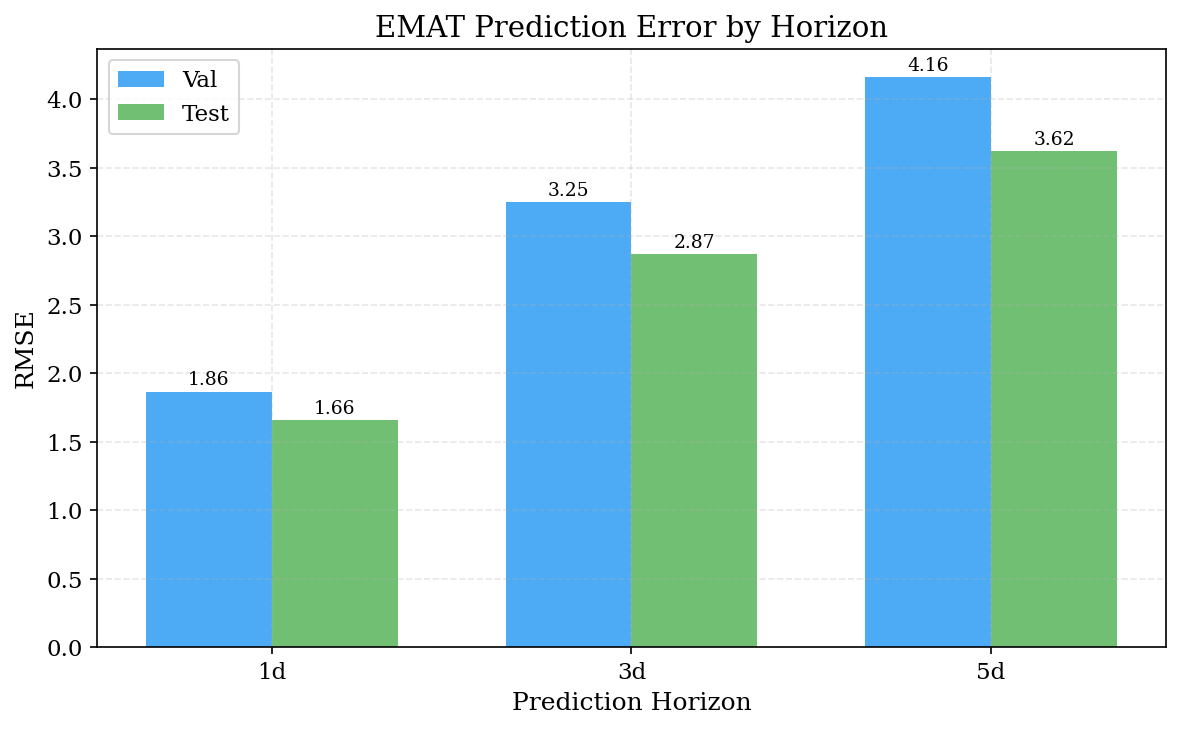

In [8]:
# Biểu đồ RMSE
horizons = ['1d', '3d', '5d']
val_rmse = [emat_metrics.get(f'val_{h}', {}).get('rmse', 0) for h in horizons]
test_rmse = [emat_metrics.get(f'test_{h}', {}).get('rmse', 0) for h in horizons]

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(horizons))
width = 0.35
ax.bar(x - width/2, val_rmse, width, label='Val', color='#2196F3', alpha=0.8)
ax.bar(x + width/2, test_rmse, width, label='Test', color='#4CAF50', alpha=0.8)
ax.set_xlabel('Prediction Horizon')
ax.set_ylabel('RMSE')
ax.set_title('EMAT Prediction Error by Horizon')
ax.set_xticks(x)
ax.set_xticklabels(horizons)
ax.legend()
for i, (v, t) in enumerate(zip(val_rmse, test_rmse)):
    ax.text(i - width/2, v + 0.05, f'{v:.2f}', ha='center', fontsize=9)
    ax.text(i + width/2, t + 0.05, f'{t:.2f}', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig(str(config.PLOTS_DIR / 'fig_emat_rmse.png'))
plt.show()

## Phase 2.2: HMM (Hidden Markov Model)

HMM phát hiện **3 regime thị trường**: Bullish 📈, Bearish 📉, Sideways ➡️

**Đặc trưng đầu vào:** Return, Volatility, Volume Change, RSI

In [9]:
from phase2_train_hmm import run as hmm_run
hmm_run()

Model is not converging.  Current: 22393.942153731434 is not greater than 22396.850521884462. Delta is -2.9083681530282774



  PHASE 2.2: HUẤN LUYỆN HMM (Market Regime Detection)

  --- AAPL ---
  Train samples: 2987
  Đang tìm số regime tốt nhất (BIC)...
    n=3: LogLik=22389.56, BIC=-44595.07, AIC=-44733.11
  ✔ Chọn n_components=3 (BIC thấp nhất)
  Regime mapping: {0: 'Bearish', 2: 'Sideways', 1: 'Bullish'}
  Phân phối regime (train):
    Bullish: 2098 (70.2%)
    Bearish: 808 (27.1%)
    Sideways: 81 (2.7%)

  --- MSFT ---
  Train samples: 2987
  Đang tìm số regime tốt nhất (BIC)...
    n=3: LogLik=23271.83, BIC=-46359.62, AIC=-46497.66
  ✔ Chọn n_components=3 (BIC thấp nhất)
  Regime mapping: {2: 'Bearish', 0: 'Sideways', 1: 'Bullish'}
  Phân phối regime (train):
    Bullish: 1944 (65.1%)
    Sideways: 853 (28.6%)
    Bearish: 190 (6.4%)

  --- JPM ---
  Train samples: 2987
  Đang tìm số regime tốt nhất (BIC)...
    n=3: LogLik=22341.30, BIC=-44498.56, AIC=-44636.60
  ✔ Chọn n_components=3 (BIC thấp nhất)
  Regime mapping: {2: 'Bearish', 1: 'Sideways', 0: 'Bullish'}
  Phân phối regime (train):
    Sidew

### Trực quan HMM Regime Detection

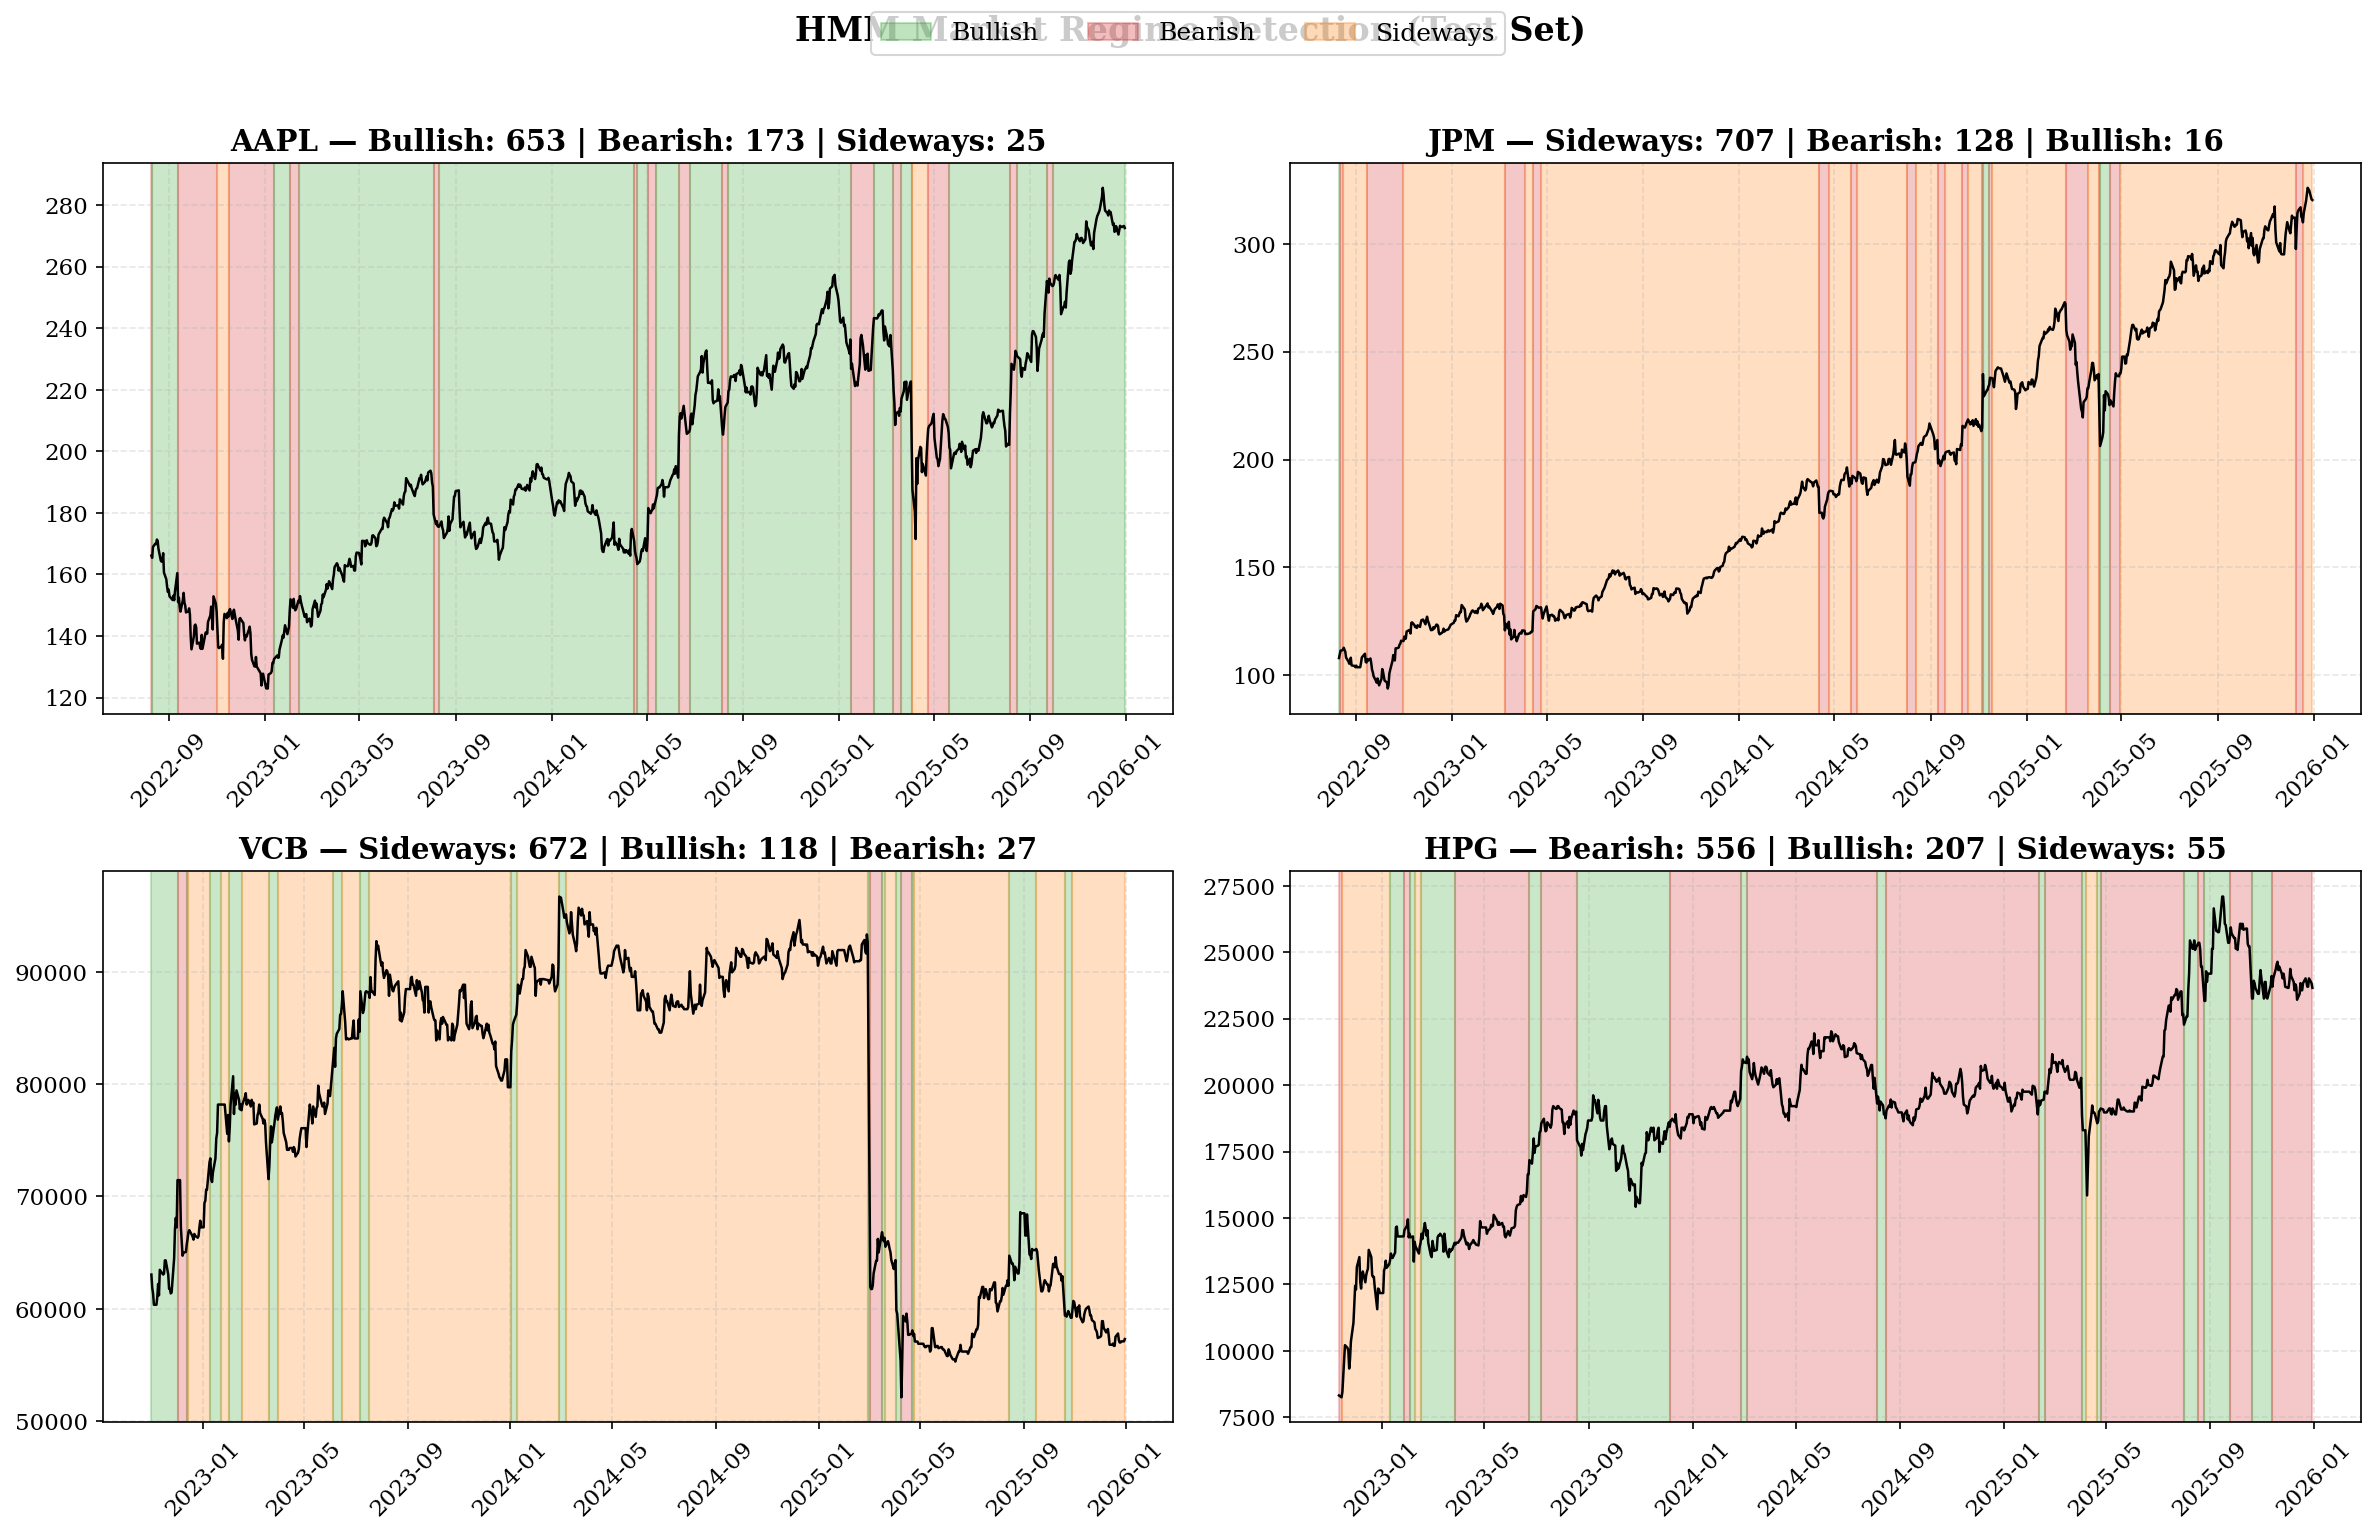

In [10]:
import pickle
from phase2_train_hmm import prepare_hmm_features

hmm_path = config.MODELS_DIR / "hmm_model.pkl"
if hmm_path.exists():
    with open(hmm_path, "rb") as f:
        hmm_models = pickle.load(f)
    
    # Chọn 4 mã đại diện
    plot_symbols = ['AAPL', 'JPM', 'VCB', 'HPG']
    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    colors = {'Bullish': '#2ca02c', 'Bearish': '#d62728', 'Sideways': '#ff7f0e'}
    
    for ax, symbol in zip(axes.flatten(), plot_symbols):
        if symbol not in hmm_models:
            continue
        
        model_data = hmm_models[symbol]
        hmm_model = model_data["model"]
        regime_map = model_data["regime_map"]
        
        price_path = config.DATA_DIR / "test" / f"{symbol}_prices.csv"
        if not price_path.exists():
            continue
        
        df = pd.read_csv(price_path)
        df['Date'] = pd.to_datetime(df['Date'])
        X, df_clean = prepare_hmm_features(df, symbol)
        states = hmm_model.predict(X)
        df_clean = df_clean.iloc[:len(states)].copy()
        df_clean['Regime'] = [regime_map[s] for s in states]
        
        ax.plot(df_clean['Date'], df_clean['Close'], color='black', linewidth=1.2)
        
        prev_regime = None
        start_idx = 0
        for i in range(1, len(df_clean)):
            curr = df_clean['Regime'].iloc[i]
            if curr != df_clean['Regime'].iloc[i-1] or i == len(df_clean)-1:
                ax.axvspan(df_clean['Date'].iloc[start_idx], df_clean['Date'].iloc[i],
                          color=colors.get(df_clean['Regime'].iloc[i-1], 'grey'), alpha=0.25)
                start_idx = i
        
        # Thống kê regime
        regime_counts = df_clean['Regime'].value_counts()
        regime_text = " | ".join([f"{k}: {v}" for k, v in regime_counts.items()])
        ax.set_title(f'{symbol} — {regime_text}', fontweight='bold')
        ax.tick_params(axis='x', rotation=45)
    
    import matplotlib.patches as mpatches
    handles = [mpatches.Patch(color=c, alpha=0.3, label=l) for l, c in colors.items()]
    fig.legend(handles=handles, loc='upper center', ncol=3, fontsize=12)
    fig.suptitle('HMM Market Regime Detection (Test Set)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.savefig(str(config.PLOTS_DIR / 'fig_hmm_regimes.png'), bbox_inches='tight')
    plt.show()

In [11]:
# HMM Diagnostics Table
print("=" * 80)
print("  HMM DIAGNOSTICS (TEST)")
print("=" * 80)
print(f"  {'Symbol':<8} | {'LL/sample':>10} | {'Persistence':>12} | {'Tail Detect':>12} | Distribution")
print(f"  {'-'*8}-+-{'-'*10}-+-{'-'*12}-+-{'-'*12}-+-{'-'*30}")

for symbol in config.SYMBOLS:
    f = config.METRICS_DIR / f"hmm_test_{symbol}.json"
    if f.exists():
        d = json.load(open(f))
        ll = d["log_likelihood_advanced"]["log_likelihood_per_sample"]
        pers = d["regime_stability"]["avg_persistence"]
        tail = d["tail_risk"]["overall_tail_detection_rate"]
        dist = d["regime_distribution"]
        dist_str = " | ".join([f"{k}: {v}" for k, v in dist.items()])
        print(f"  {symbol:<8} | {ll:>10.4f} | {pers:>12.4f} | {tail:>11.1%} | {dist_str}")

  HMM DIAGNOSTICS (TEST)
  Symbol   |  LL/sample |  Persistence |  Tail Detect | Distribution
  ---------+------------+--------------+--------------+-------------------------------
  AAPL     |     7.5907 |       0.9267 |       39.5% | Bullish: 653 | Bearish: 173 | Sideways: 25
  MSFT     |     7.7666 |       0.9353 |       14.0% | Bullish: 527 | Sideways: 289 | Bearish: 35
  JPM      |     7.7624 |       0.9656 |       41.9% | Sideways: 707 | Bearish: 128 | Bullish: 16
  XOM      |     7.7216 |       0.9609 |       45.3% | Bearish: 430 | Bullish: 403 | Sideways: 18
  VCB      |     7.3990 |       0.9169 |       43.9% | Sideways: 672 | Bullish: 118 | Bearish: 27
  HPG      |     7.4387 |       0.9272 |       30.5% | Bearish: 556 | Bullish: 207 | Sideways: 55
  FPT      |     7.6642 |       0.9315 |       54.9% | Sideways: 502 | Bullish: 296 | Bearish: 20


## Phase 2.3: GARCH (Volatility Forecasting)

GARCH(1,1) dự báo conditional volatility cho từng mã.

In [12]:
from phase2_train_garch import run as garch_run
garch_run()


  PHASE 2.3: HUẤN LUYỆN GARCH (Volatility Forecasting)

  --- AAPL ---
  Samples: 2991 | RMSE: 0.6229 | AIC: 11548.55 | BIC: 11572.57
  Params: omega=0.190986, alpha=0.122439, beta=0.820805
  Vol distribution (Z-score): {'Trung bình': 1943, 'Cao': 550, 'Thấp': 498}

  --- MSFT ---
  Samples: 2991 | RMSE: 0.5954 | AIC: 10931.67 | BIC: 10955.69
  Params: omega=0.189935, alpha=0.133867, beta=0.798613
  Vol distribution (Z-score): {'Trung bình': 1991, 'Thấp': 525, 'Cao': 475}

  --- JPM ---
  Samples: 2991 | RMSE: 0.7415 | AIC: 11445.34 | BIC: 11469.35
  Params: omega=0.081665, alpha=0.111096, beta=0.865138
  Vol distribution (Z-score): {'Trung bình': 1743, 'Thấp': 718, 'Cao': 530}

  --- XOM ---
  Samples: 2991 | RMSE: 0.4768 | AIC: 9633.96 | BIC: 9657.97
  Params: omega=0.028639, alpha=0.098030, beta=0.889623
  Vol distribution (Z-score): {'Trung bình': 1559, 'Thấp': 809, 'Cao': 623}

  --- VCB ---
  Samples: 2872 | RMSE: 0.7200 | AIC: 11628.04 | BIC: 11651.89
  Params: omega=0.159490, 

In [13]:
# GARCH Comparison Table
print("=" * 60)
print("  GARCH RMSE")
print("=" * 60)
print(f"  {'Symbol':<8} | {'Val RMSE':>10} | {'Test RMSE':>10}")
print(f"  {'-'*8}-+-{'-'*10}-+-{'-'*10}")

garch_data = {}
for symbol in config.SYMBOLS:
    row = {"symbol": symbol}
    for split in ['val', 'test']:
        f = config.METRICS_DIR / f"garch_{split}_{symbol}.json"
        if f.exists():
            d = json.load(open(f))
            row[f"{split}_rmse"] = d["rmse"]
    garch_data[symbol] = row
    print(f"  {symbol:<8} | {row.get('val_rmse', 0):>10.4f} | {row.get('test_rmse', 0):>10.4f}")

  GARCH RMSE
  Symbol   |   Val RMSE |  Test RMSE
  ---------+------------+-----------
  AAPL     |     0.5889 |     0.7090
  MSFT     |     0.5424 |     0.6586
  JPM      |     0.5470 |     0.6434
  XOM      |     0.6603 |     0.5352
  VCB      |     0.6723 |     1.0279
  HPG      |     0.8650 |     0.7075
  FPT      |     0.6232 |     0.6327


## Phase 2.4: Sentiment (XLM-RoBERTa + CNN + BiGRU)

Phân loại sentiment tin tức thành 3 lớp: **Tích cực** / **Tiêu cực** / **Trung tính**

**Backbone:** xlm-roberta-base (đa ngôn ngữ VI/EN)  
**Head:** CNN (n-gram features) + BiGRU (sequential context)

In [16]:
from phase2_train_sentiment import run as sentiment_run
sentiment_run()


  PHASE 2.4: HUẤN LUYỆN SENTIMENT (XLM-RoBERTa + CNN + BiGRU)
  Device: cuda
  Backbone: xlm-roberta-base
  Đang load dữ liệu train...
  Train: 8008 samples
  Val  : 728 samples
  Phân phối: Tích cực=1168, Tiêu cực=70, Trung tính=6770
  Parameters: 44,005,635 trainable / 278,931,459 total


KeyboardInterrupt: 

### Confusion Matrix & Classification Report


  SENTIMENT VAL: Acc=0.8393 | F1=0.8406
  Tích cực        P=0.7745 R=0.8256 F1=0.7992 N=258.0
  Tiêu cực        P=0.5263 R=0.5882 F1=0.5556 N=17.0
  Trung tính      P=0.8940 R=0.8565 F1=0.8749 N=453.0
  macro avg       P=0.7316 R=0.7568 F1=0.7432 N=728.0
  weighted avg    P=0.8431 R=0.8393 F1=0.8406 N=728.0


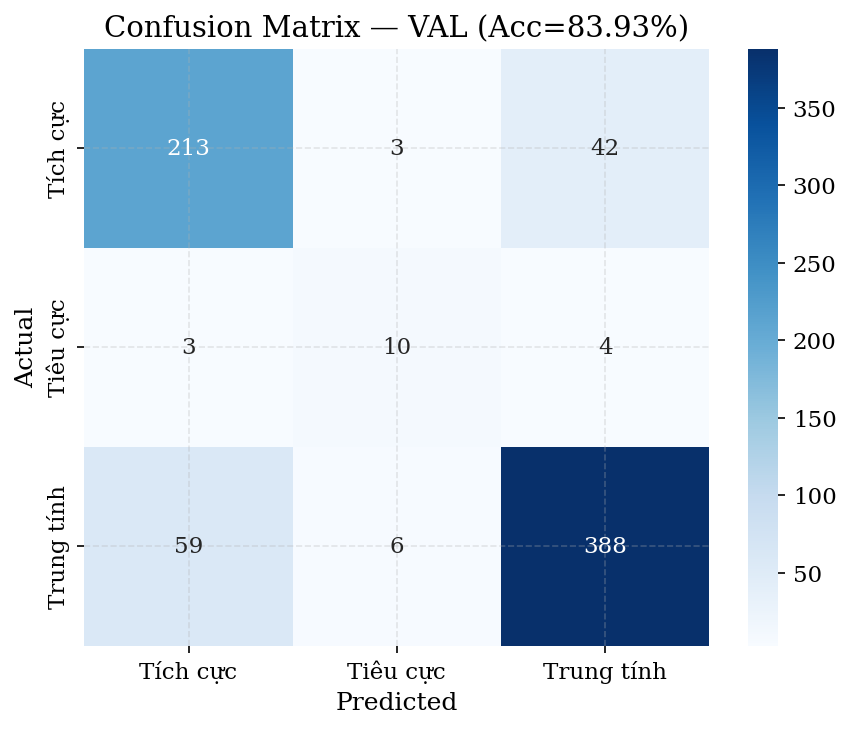


  SENTIMENT TEST: Acc=0.8829 | F1=0.8817
  Tích cực        P=0.6942 R=0.8216 F1=0.7525 N=1710.0
  Tiêu cực        P=0.5993 R=0.3763 F1=0.4624 N=465.0
  Trung tính      P=0.9418 R=0.9253 F1=0.9335 N=8031.0
  macro avg       P=0.7451 R=0.7078 F1=0.7161 N=10206.0
  weighted avg    P=0.8847 R=0.8829 F1=0.8817 N=10206.0


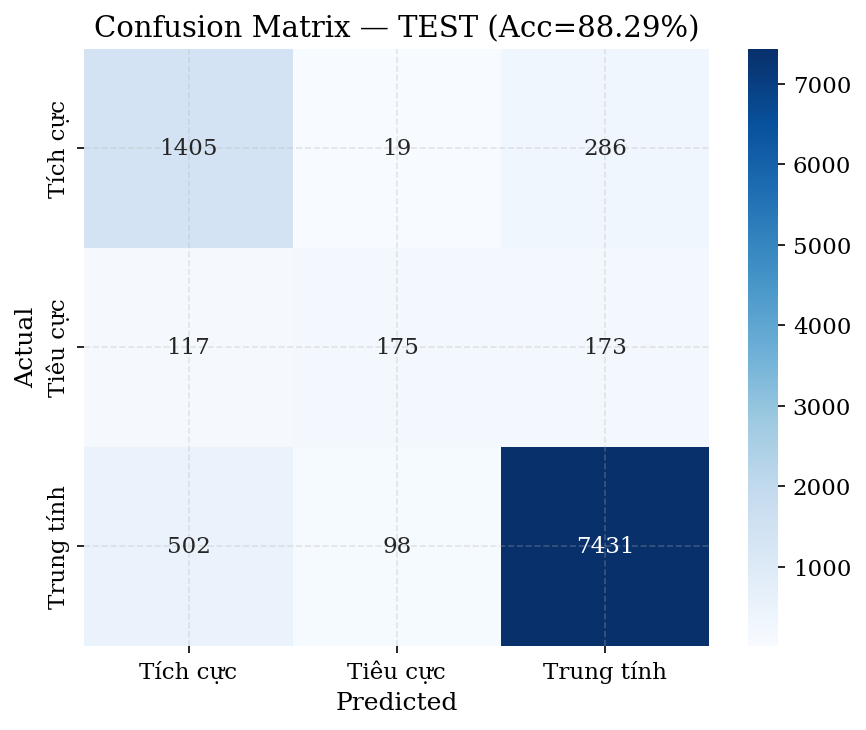

In [17]:
from sklearn.metrics import ConfusionMatrixDisplay

for split in ['val', 'test']:
    f = config.METRICS_DIR / f"sentiment_{split}.json"
    if not f.exists():
        continue
    d = json.load(open(f))
    print(f"\n{'='*50}")
    print(f"  SENTIMENT {split.upper()}: Acc={d['acc']:.4f} | F1={d['f1']:.4f}")
    print(f"{'='*50}")
    
    if 'report' in d:
        for cls_name, cls_data in d['report'].items():
            if isinstance(cls_data, dict) and 'precision' in cls_data:
                print(f"  {cls_name:<15} P={cls_data['precision']:.4f} R={cls_data['recall']:.4f} F1={cls_data['f1-score']:.4f} N={cls_data['support']}")
    
    if 'cm' in d:
        cm = np.array(d['cm'])
        fig, ax = plt.subplots(figsize=(6, 5))
        labels = ['Tích cực', 'Tiêu cực', 'Trung tính']
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
        ax.set_title(f'Confusion Matrix — {split.upper()} (Acc={d["acc"]:.2%})')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('Actual')
        plt.tight_layout()
        plt.savefig(str(config.PLOTS_DIR / f'fig_cm_{split}.png'))
        plt.show()

## Phase 3: Generate State Vectors

Gộp output từ 4 models (EMAT + HMM + GARCH + Sentiment) thành **state vector 28 chiều** cho RL Agent.

In [18]:
from phase3_generate_states import run as phase3_run
phase3_run()

# Kiểm tra states
print("\nState Vector Summary:")
for split in ['train', 'val', 'test']:
    obs = np.load(config.STATES_DIR / f"{split}_observations.npy")
    print(f"  {split}: shape={obs.shape} | NaN={np.isnan(obs).sum()} | Inf={np.isinf(obs).sum()}")


  PHASE 3: SINH STATE VECTORS

  Loading models...
  ✔ EMAT loaded
  ✔ HMM loaded
  ✔ GARCH loaded
  ✔ Sentiment loaded

  --- TRAIN ---
    AAPL... OK (2992 days, state_dim=28)
    MSFT... OK (2992 days, state_dim=28)
    JPM... OK (2992 days, state_dim=28)
    XOM... OK (2992 days, state_dim=28)
    VCB... OK (2873 days, state_dim=28)
    HPG... OK (2879 days, state_dim=28)
    FPT... OK (2879 days, state_dim=28)
    Tổng: 20599 samples, 28 dims

  --- VAL ---
    AAPL... OK (427 days, state_dim=28)
    MSFT... OK (427 days, state_dim=28)
    JPM... OK (427 days, state_dim=28)
    XOM... OK (427 days, state_dim=28)
    VCB... OK (410 days, state_dim=28)
    HPG... OK (412 days, state_dim=28)
    FPT... OK (412 days, state_dim=28)
    Tổng: 2942 samples, 28 dims

  --- TEST ---
    AAPL... OK (856 days, state_dim=28)
    MSFT... OK (856 days, state_dim=28)
    JPM... OK (856 days, state_dim=28)
    XOM... OK (856 days, state_dim=28)
    VCB... OK (822 days, state_dim=28)
    HPG... O

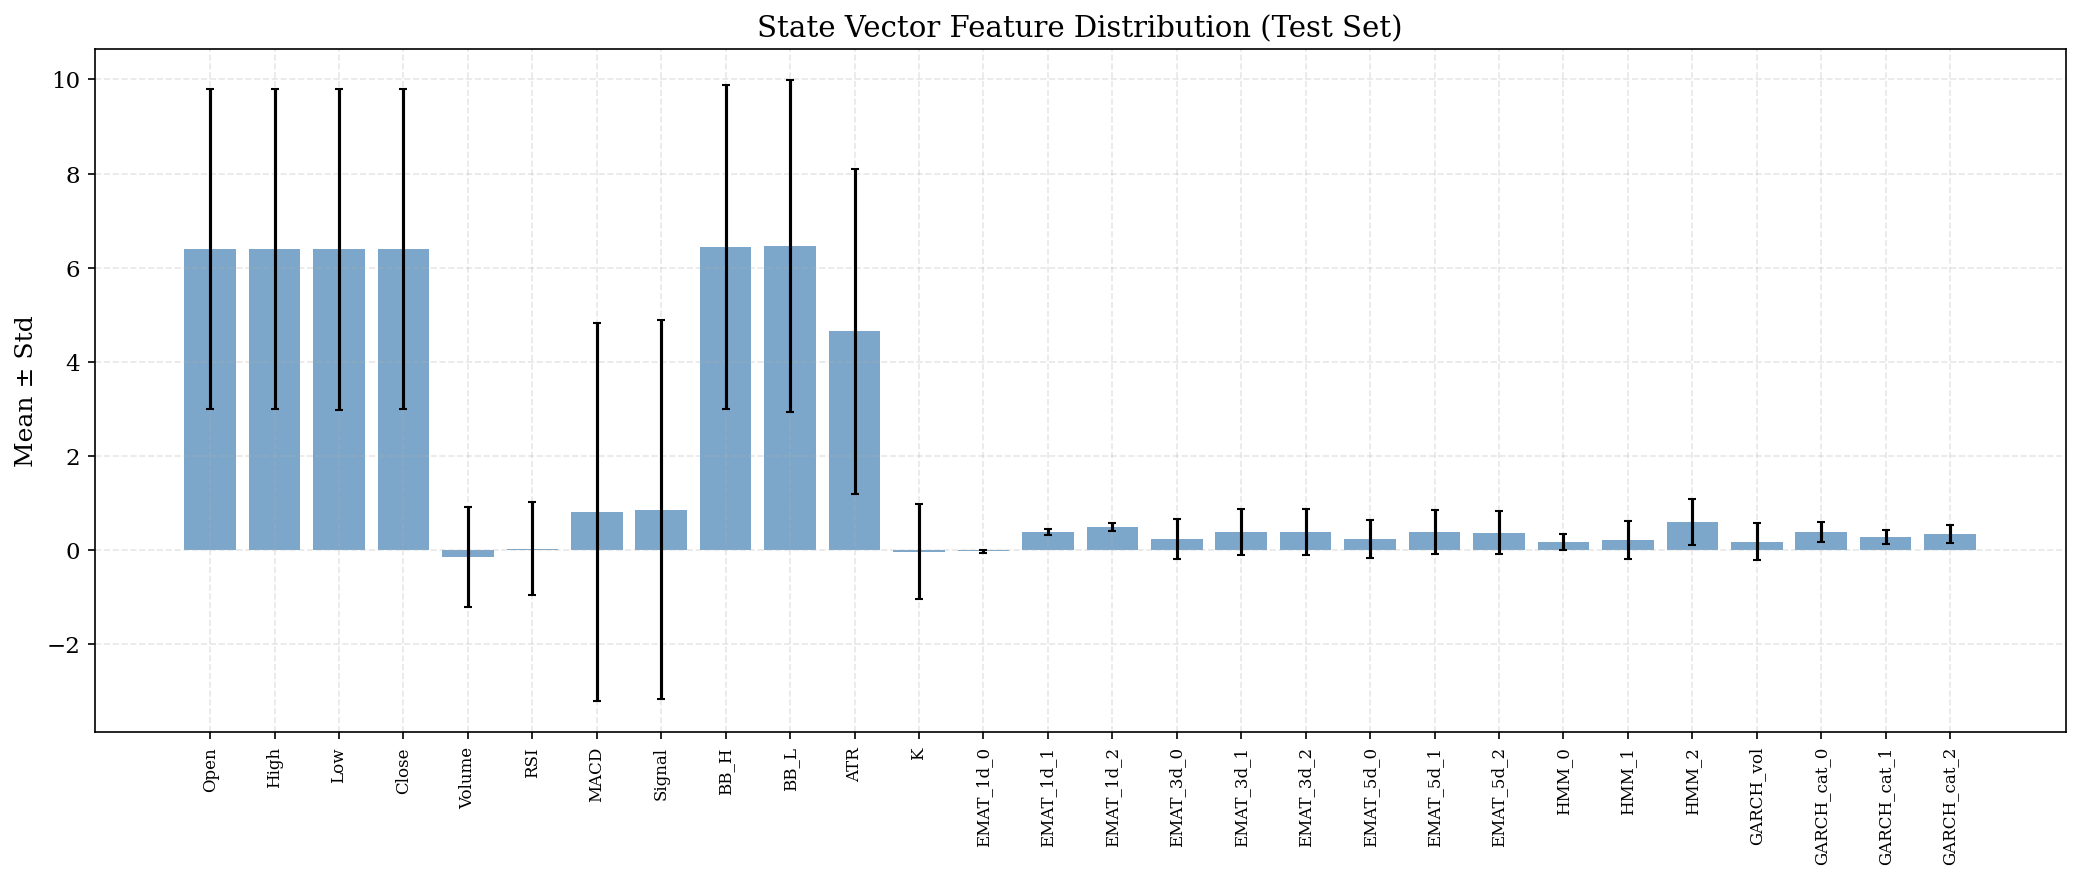

In [19]:
# Trực quan phân bố state features
obs_test = np.load(config.STATES_DIR / "test_observations.npy")
feature_names = [
    'Open', 'High', 'Low', 'Close', 'Volume',
    'RSI', 'MACD', 'Signal', 'BB_H', 'BB_L', 'ATR', 'K',
    'EMAT_1d_0', 'EMAT_1d_1', 'EMAT_1d_2',
    'EMAT_3d_0', 'EMAT_3d_1', 'EMAT_3d_2',
    'EMAT_5d_0', 'EMAT_5d_1', 'EMAT_5d_2',
    'HMM_0', 'HMM_1', 'HMM_2',
    'GARCH_vol', 'GARCH_cat_0', 'GARCH_cat_1', 'GARCH_cat_2',
]

fig, ax = plt.subplots(figsize=(14, 6))
means = obs_test.mean(axis=0)
stds = obs_test.std(axis=0)
x = range(len(means))
ax.bar(x, means, yerr=stds, alpha=0.7, capsize=2, color='steelblue')
ax.set_xticks(x)
ax.set_xticklabels(feature_names[:len(means)], rotation=90, fontsize=8)
ax.set_title('State Vector Feature Distribution (Test Set)')
ax.set_ylabel('Mean ± Std')
plt.tight_layout()
plt.savefig(str(config.PLOTS_DIR / 'fig_state_features.png'))
plt.show()

## Phase 4: Huấn luyện Hybrid DQN-PPO Agent

**Giai đoạn 1 — DQN:** Agent học phân biệt Mua/Bán qua Q-learning  
**Giai đoạn 2 — PPO:** Agent học quản lý rủi ro qua Policy Gradient

> ⚠️ **Lưu ý:** Phase này mất ~1-2 ngày trên GPU.

In [ ]:
from phase4_train_agent import run as phase4_run
phase4_run()

## 📊 Đánh giá tổng hợp — Kết quả cuối cùng

### Agent Performance

In [ ]:
# Đọc kết quả Agent
for split in ['val', 'test']:
    f = config.METRICS_DIR / f"agent_backtest_{split}.json"
    if not f.exists():
        print(f"  {split}: Chưa có kết quả")
        continue
    d = json.load(open(f))
    print(f"\n{'='*60}")
    print(f"  AGENT PERFORMANCE — {split.upper()}")
    print(f"{'='*60}")
    print(f"  Total Return    : {d.get('total_return', 0)*100:>+8.2f}%")
    print(f"  Annual Return   : {d.get('annualized_return', 0)*100:>+8.2f}%")
    print(f"  Sharpe Ratio    : {d.get('sharpe_ratio', 0):>8.4f}")
    print(f"  Sortino Ratio   : {d.get('sortino_ratio', 0):>8.4f}")
    print(f"  Max Drawdown    : {d.get('max_drawdown', 0)*100:>8.2f}%")
    print(f"  Calmar Ratio    : {d.get('calmar_ratio', 0):>8.4f}")
    print(f"  Win Rate        : {d.get('win_rate', 0)*100:>8.2f}%")
    print(f"  Profit Factor   : {d.get('profit_factor', 0):>8.4f}")
    print(f"  Final Value     : ${d.get('final_value', 0):>12,.2f}")
    print(f"  Buy&Hold Return : {d.get('buy_hold_return', 0)*100:>+8.2f}%")

### Baseline Comparison (10 mã)

In [ ]:
from run_baseline_comparison import run as baseline_run
baseline_run()

In [ ]:
# Đọc và trực quan baseline
baseline_file = config.METRICS_DIR / "baseline_comparison.json"
if baseline_file.exists():
    baselines = json.load(open(baseline_file))
    
    # Tính trung bình cho từng strategy
    summary = {}
    for strat, results in baselines.items():
        if results:
            summary[strat] = {
                'avg_return': np.mean([m['total_return'] for m in results.values()]),
                'avg_sharpe': np.mean([m['sharpe_ratio'] for m in results.values()]),
                'avg_mdd': np.mean([m['max_drawdown'] for m in results.values()]),
            }
    
    # Bar chart so sánh
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    strats = list(summary.keys())
    
    # Return
    returns = [summary[s]['avg_return'] * 100 for s in strats]
    colors = ['#4CAF50' if r > 0 else '#F44336' for r in returns]
    axes[0].barh(strats, returns, color=colors, alpha=0.8)
    axes[0].set_title('Average Return (%)', fontweight='bold')
    axes[0].axvline(0, color='black', linewidth=0.5)
    for i, v in enumerate(returns):
        axes[0].text(v + 1, i, f'{v:+.1f}%', va='center', fontsize=10)
    
    # Sharpe
    sharpes = [summary[s]['avg_sharpe'] for s in strats]
    axes[1].barh(strats, sharpes, color='#2196F3', alpha=0.8)
    axes[1].set_title('Average Sharpe Ratio', fontweight='bold')
    for i, v in enumerate(sharpes):
        axes[1].text(v + 0.02, i, f'{v:.2f}', va='center', fontsize=10)
    
    # MDD
    mdds = [summary[s]['avg_mdd'] * 100 for s in strats]
    axes[2].barh(strats, mdds, color='#FF9800', alpha=0.8)
    axes[2].set_title('Average Max Drawdown (%)', fontweight='bold')
    for i, v in enumerate(mdds):
        axes[2].text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=10)
    
    plt.suptitle('Baseline Comparison — 10 Symbols', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.savefig(str(config.PLOTS_DIR / 'fig_baseline_comparison.png'))
    plt.show()

### Per-Symbol Baseline Heatmap

In [ ]:
if baseline_file.exists():
    # Heatmap return theo symbol × strategy
    symbols_all = set()
    for strat_data in baselines.values():
        symbols_all.update(strat_data.keys())
    symbols_all = sorted(symbols_all)
    strats = list(baselines.keys())
    
    data = np.zeros((len(symbols_all), len(strats)))
    for j, strat in enumerate(strats):
        for i, sym in enumerate(symbols_all):
            if sym in baselines[strat]:
                data[i, j] = baselines[strat][sym]['total_return'] * 100
    
    fig, ax = plt.subplots(figsize=(12, 8))
    sns.heatmap(data, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
                xticklabels=strats, yticklabels=symbols_all, ax=ax,
                linewidths=0.5, cbar_kws={'label': 'Return (%)'})
    ax.set_title('Return (%) by Symbol × Strategy', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(str(config.PLOTS_DIR / 'fig_baseline_heatmap.png'))
    plt.show()

### Cumulative Returns — Agent vs Buy & Hold

In [ ]:
import torch
from phase3_trading_env import HybridTradingEnv
from phase4_hybrid_agent import HybridAgent

agent_path = config.MODELS_DIR / "hybrid_agent_final.pth"
if agent_path.exists():
    env = HybridTradingEnv(split="test")
    agent = HybridAgent(env.state_dim).to(config.DEVICE)
    agent.load_state_dict(torch.load(agent_path, map_location=config.DEVICE))
    agent.eval()
    
    state, _ = env.reset()
    done = False
    while not done:
        state_tensor = torch.tensor(state, dtype=torch.float32).unsqueeze(0).to(config.DEVICE)
        with torch.no_grad():
            q_values = agent.get_q_values(state_tensor)
            action = q_values.argmax(dim=-1).item()
        state, _, terminated, truncated, _ = env.step(action)
        done = terminated or truncated
    
    # Plot
    values = [t['portfolio_value'] for t in env.trade_history]
    steps = range(len(values))
    bh_values = [env.initial_balance * env.prices[t['step']] / env.prices[0] for t in env.trade_history]
    
    agent_returns = [(v - env.initial_balance) / env.initial_balance * 100 for v in values]
    bh_returns = [(v - env.initial_balance) / env.initial_balance * 100 for v in bh_values]
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), gridspec_kw={'height_ratios': [3, 1]})
    
    ax1.plot(steps, agent_returns, color='#1565C0', linewidth=2, label='Hybrid DQN-PPO Agent')
    ax1.plot(steps, bh_returns, color='#757575', linewidth=1.5, linestyle='--', label='Buy & Hold', alpha=0.7)
    ax1.fill_between(steps, agent_returns, alpha=0.1, color='#1565C0')
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title('Cumulative Return — Agent vs Buy & Hold (Test Set)', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Cumulative Return (%)')
    ax1.legend(fontsize=12)
    
    # Drawdown
    peak = np.maximum.accumulate(values)
    dd = [(peak[i] - values[i]) / peak[i] * 100 for i in range(len(values))]
    ax2.fill_between(steps, dd, color='#F44336', alpha=0.4)
    ax2.set_ylabel('Drawdown (%)')
    ax2.set_xlabel('Trading Steps')
    ax2.set_title('Drawdown Analysis')
    ax2.invert_yaxis()
    
    plt.tight_layout()
    plt.savefig(str(config.PLOTS_DIR / 'fig_cumulative_returns.png'))
    plt.show()
    
    print(f"\nAgent Final Return: {agent_returns[-1]:+.2f}%")
    print(f"B&H Final Return: {bh_returns[-1]:+.2f}%")
    print(f"Max Drawdown: {max(dd):.2f}%")
else:
    print("Agent model chưa được train. Chạy Phase 4 trước.")

## 📋 Bảng tổng kết toàn bộ Pipeline

In [ ]:
print("=" * 70)
print("  TỔNG KẾT PIPELINE EMAT HYBRID")
print("=" * 70)

# EMAT
print("\n📊 EMAT (Time2Vec + Transformer):")
for h in ['1d', '3d', '5d']:
    f = config.METRICS_DIR / f"emat_test_{h}.json"
    if f.exists():
        d = json.load(open(f))
        print(f"  {h}: RMSE={d['rmse']:.4f} | MAE={d['mae']:.4f}")

# HMM
print("\n🔄 HMM (Regime Detection):")
for sym in config.SYMBOLS:
    f = config.METRICS_DIR / f"hmm_test_{sym}.json"
    if f.exists():
        d = json.load(open(f))
        pers = d["regime_stability"]["avg_persistence"]
        tail = d["tail_risk"]["overall_tail_detection_rate"]
        print(f"  {sym}: Persistence={pers:.4f} | Tail={tail:.1%}")

# GARCH
print("\n📈 GARCH (Volatility):")
for sym in config.SYMBOLS:
    f = config.METRICS_DIR / f"garch_test_{sym}.json"
    if f.exists():
        d = json.load(open(f))
        print(f"  {sym}: RMSE={d['rmse']:.4f}")

# Sentiment
print("\n💬 Sentiment (XLM-RoBERTa + CNN + BiGRU):")
for split in ['val', 'test']:
    f = config.METRICS_DIR / f"sentiment_{split}.json"
    if f.exists():
        d = json.load(open(f))
        print(f"  {split.upper()}: Acc={d['acc']:.4f} | F1={d['f1']:.4f}")

# Agent
print("\n🤖 Hybrid DQN-PPO Agent:")
for split in ['val', 'test']:
    f = config.METRICS_DIR / f"agent_backtest_{split}.json"
    if f.exists():
        d = json.load(open(f))
        print(f"  {split.upper()}: Return={d.get('total_return',0)*100:+.2f}% | Sharpe={d.get('sharpe_ratio',0):.4f} | MDD={d.get('max_drawdown',0)*100:.2f}%")

print("\n" + "=" * 70)
print("  ✔ PIPELINE HOÀN TẤT")
print("=" * 70)